# PHYS 690 - Lecture 16: Stochastic Simulation and Uncertainty Propagation

## From Monte Carlo averages to simulated measurements

In Lecture 15, we drew random delays $T_i$ and averaged the deterministic model probabilities $p_e(T_i)$ to estimate the average excitation probability. Those draws approximated an integral; they did not simulate detector readouts.

Today, the delay values $t_i$ and shot counts $n_i$ define the measurement design. At each fixed delay, the individual readouts are random binary outcomes. With $\boldsymbol{\theta}=(C,\tau,\omega,\phi)$, the shared model is

$$
p_e(t\mid\boldsymbol{\theta})=\frac{1}{2}\left[1+C e^{-t/\tau}\cos(\omega t+\phi)\right].
$$

For $n_i$ shots at delay $t_i$, the excited count $K_i$ follows a binomial distribution with $n_i$ trials and success probability $p_e(t_i\mid\boldsymbol{\theta})$. This describes experimental shot noise or statistical uncertainty. Repeating the simulation estimates the distribution of possible results; using a finite number of repeats leaves some Monte Carlo error in that estimate. We will keep shot noise, parameter uncertainty, and Monte Carlo error distinct.

## Learning goals and class plan

By the end of class, you should be able to:

1. simulate binomial measurement outcomes;
2. connect binomial mean and variance to observed proportions;
3. use repeated simulation to approximate a sampling distribution;
4. draw correlated uncertain parameters from a covariance matrix; and
5. compare linear covariance propagation with full Monte Carlo propagation.

In [ ]:
# NumPy handles arrays and random draws; pandas organizes results; Matplotlib plots.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use consistent figure styling throughout the lecture.
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

## Part 1: The data-generating process

We use the same damped Ramsey model and parameter vector as Lecture 15:

$$
p_e(t\mid\boldsymbol{\theta})=\frac{1}{2}\left[1+C e^{-t/\tau}\cos(\omega t+\phi)\right],
\qquad \boldsymbol{\theta}=(C,\tau,\omega,\phi).
$$

At a chosen delay $t_i$, let $p_i=p_e(t_i\mid\boldsymbol{\theta})$. Each of the $n_i$ independent shots has two possible outcomes: an excited result with probability $p_i$, or a non-excited result with probability $1-p_i$. The total excited count $K_i$ therefore follows a binomial distribution with $n_i$ shots and success probability $p_i$.

Across many repeated sets of $n_i$ shots, the average count is $n_i p_i$ and the count variance is $n_i p_i(1-p_i)$. The measured fraction and its standard deviation are

$$
\widehat p_i=\frac{K_i}{n_i},\qquad
\text{standard deviation of }\widehat p_i=\sqrt{\frac{p_i(1-p_i)}{n_i}}.
$$

This is **physical shot noise** at a fixed delay. It differs from Lecture 15's Monte Carlo standard error $s_p/\sqrt{N}$, where $N$ counted random delay samples used to estimate an average of the model curve.

Because this is synthetic data, the generating probability $p_i$ is known and can be used to show the expected shot-noise scale. In a real measurement, it would be unknown and estimated from the observed proportion.

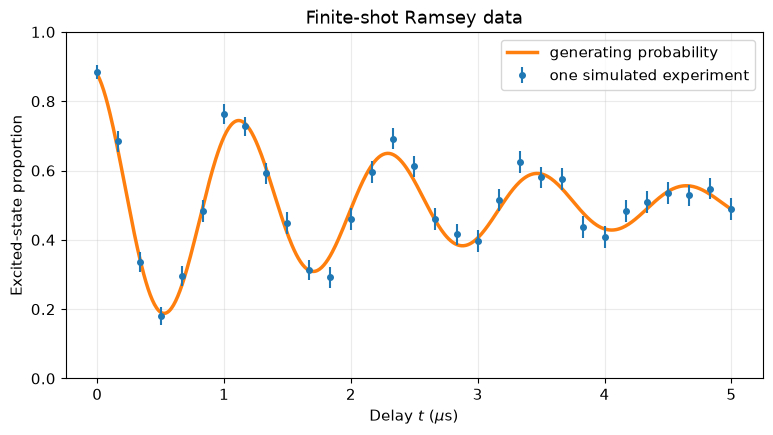

In [3]:
# Define the same Ramsey probability function used in Lecture 15.
def ramsey_probability(t, contrast, tau, omega, phase):
    # Model the decaying fringe envelope and its oscillating phase separately.
    envelope = np.exp(-np.asarray(t) / tau)
    oscillation = np.cos(omega * np.asarray(t) + phase)
    # Return the predicted excited-state probability (without altering the model).
    return 0.5 * (1.0 + contrast * envelope * oscillation)


# Reuse Lecture 15's generating parameters
true_parameters = {
    "contrast": 0.78,
    "tau": 2.40,                  # microseconds
    "omega": 2.0 * np.pi * 0.85,  # radians per microsecond
    "phase": 0.25,                # radians
}

# Choose fixed measurement delays and a fixed number of physical shots per delay.
delays = np.linspace(0.0, 5.0, 31)
shots_per_delay = 250
# Compute the generating probability at each design delay.
true_probability = ramsey_probability(delays, **true_parameters)

# Draw one binomial count at every delay to create one synthetic experiment.
experiment_rng = np.random.default_rng(1601)
excited_counts = experiment_rng.binomial(shots_per_delay, true_probability)

# Keep the design, counts, observed proportions, and known generating truth together.
experiment_df = pd.DataFrame({
    "time_us": delays,
    "shots": shots_per_delay,
    "excited_counts": excited_counts,
    "measured_probability": excited_counts / shots_per_delay,
    "true_probability": true_probability,
})
# Compute the expected standard error of each proportion using the known synthetic truth.
experiment_df["binomial_standard_error"] = np.sqrt(
    experiment_df["true_probability"]
    * (1.0 - experiment_df["true_probability"])
    / experiment_df["shots"]
)

# Evaluate the same generating model on a dense grid for a smooth orange curve.
model_time_us = np.linspace(delays.min(), delays.max(), 600)
model_curve_df = pd.DataFrame({
    "time_us": model_time_us,
    "true_probability": ramsey_probability(model_time_us, **true_parameters),
})

# Compare one finite-shot dataset with the smooth curve that generated it.
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(model_curve_df["time_us"], model_curve_df["true_probability"],
        color="tab:orange", lw=2.5, label="generating probability")
ax.errorbar(experiment_df["time_us"], experiment_df["measured_probability"],
            yerr=experiment_df["binomial_standard_error"], fmt="o", ms=4,
            label="one simulated experiment")
ax.set(xlabel=r"Delay $t$ ($\mu$s)", ylabel="Excited-state proportion",
       title="Finite-shot Ramsey data")
ax.set_ylim(0.0, 1.0)
ax.legend()
plt.show()

### A simulation is a generative model

The code follows the probability statement in order:

1. choose fixed design values $t_i$ and shot counts $n_i$;
2. evaluate the physical probability $p_i=p_e(t_i\mid\boldsymbol{\theta})$;
3. draw the excited count $K_i$ from a binomial distribution with $n_i$ shots and success probability $p_i$.

This differs from Lecture 15: there, the random variables were delay points used to average a known probability curve; here, the delays are fixed and the random variables are the detector outcomes. The number of Monte Carlo repetitions controls how accurately we estimate a sampling distribution, while the number of physical shots controls the shot noise within each simulated experiment.

Keeping these layers separate will make the likelihood in Lecture 17 almost automatic.

**Discuss:** If you change the random seed and rerun the code, which columns in `experiment_df` should stay the same? Which should change?

In [ ]:
display(experiment_df)

## Part 2: In-class coding activity 1 - Repeated experiments

**Time: 13 minutes. Work in pairs.**

Focus on the delay nearest $t=0$, where $p_e$ is most sensitive to contrast. Simulate 3000 independent synthetic experiments with 250 physical shots in each one. For every experiment, convert the excited count to a measured proportion. Compare the empirical mean and standard deviation of those proportions with the binomial predictions.

The 3000 repetitions approximate the physical sampling distribution; they are not 3000 shots in one experiment. The standard deviation across repetitions should approach the predicted shot-noise standard deviation as the number of repetitions grows.

In [ ]:
# Fix the activity's pseudo-random stream and define the repeated-experiment design.
activity_rng = np.random.default_rng(1616)
activity_repetitions = 3000
activity_shots = 250
activity_t = 0.0
# Evaluate the physical model once; each repeated experiment uses this probability.
activity_p = ramsey_probability(activity_t, **true_parameters)

# TODO: Draw one binomial count for each independent synthetic experiment (Hint: use activity_rng.binomial(activity_shots, activity_p, size=activity_repetitions)).
activity_counts = ...
# TODO: Divide each count by the number of shots to form measured proportions.
activity_proportions = ...
# TODO: Compute the empirical mean and sample standard deviation across repetitions.
activity_empirical_mean = ...
activity_empirical_std = ...

# The theoretical mean and standard deviation for one measured proportion.
activity_theory_summary = np.array([
    activity_p,
    np.sqrt(activity_p * (1.0 - activity_p) / activity_shots),
])

# Compare simulated summaries with their binomial predictions in a readable table.
repeated_summary_df = pd.DataFrame({
    "quantity": ["mean proportion", "standard deviation"],
    "simulation": [activity_empirical_mean, activity_empirical_std],
    "binomial prediction": activity_theory_summary,
})
# Store the distribution of proportions for the histogram below.
activity_results_df = pd.DataFrame({"measured_proportion": activity_proportions})
display(repeated_summary_df)

# Show the sampling distribution across repeated synthetic experiments.
fig, ax = plt.subplots()
ax.hist(activity_results_df["measured_proportion"], bins=30, density=True, alpha=0.7)
ax.axvline(activity_p, color="black", ls="--", label="true probability")
ax.set(xlabel="Measured proportion", ylabel="Density",
       title="Sampling distribution from repeated experiments")
ax.legend()
plt.show()

## Part 3: Propagating correlated calibration uncertainty

Lecture 15 used the fixed generating parameter vector $\boldsymbol{\theta}=(C,\tau,\omega,\phi)$. Lecture 4 introduced `curve_fit`, which returns `popt` and `pcov`: `popt` contains the fitted parameter values, and `pcov` is the covariance matrix for those parameter estimates. Its diagonal entries are parameter variances (so their square roots are the one-standard-deviation uncertainties); its off-diagonal entries are parameter covariances.

Here, a separate calibration constrains $\tau$ and the contrast $C$. We will use a covariance matrix of the same kind as Lecture 4's `pcov`, and call the matrix `pcov` in the code. To focus on uncertainty propagation, we specify this example matrix directly from assumed standard deviations and a correlation coefficient; it is not returned by a new `curve_fit` call. The parameter order is $(\tau,C)$, so the diagonal entries are $\sigma_\tau^2$ and $\sigma_C^2$, and the off-diagonal entries are $\rho\sigma_\tau\sigma_C$.

The off-diagonal entries record how $\tau$ and $C$ vary together. Drawing the parameters independently would discard this information. We propagate the correlated draws through $g(\tau,C)=p_e(t_\star\mid\tau,C,\omega,\phi)$, holding $\omega$ and $\phi$ at their Lecture 15 generating values.

For small uncertainties, Lecture 4's first-order propagation combines the model's sensitivity to each parameter with the variances and covariance in `pcov`. Writing $g_\tau=\partial g/\partial\tau$ and $g_C=\partial g/\partial C$, the two-parameter formula is

$$
\sigma_g^2\approx g_\tau^2\sigma_\tau^2+g_C^2\sigma_C^2
+2g_\tau g_C\,\mathrm{cov}(\tau,C).
$$

Monte Carlo propagation evaluates the full nonlinear model at sampled parameter pairs. It can reveal skewness or boundary effects that this local, linear approximation misses.

### Reading and validating the covariance model

The diagonal entries of `pcov` are variances and the off-diagonal entries are covariances, just as in Lecture 4. A covariance matrix must be symmetric and positive semidefinite. Before sampling, check its eigenvalues and confirm that the implied draws remain physically plausible. A multivariate normal can produce $C<0$ or $C>1$ even when its mean is physical; a bounded distribution or transformed parameter may be preferable when that probability is not negligible.

Correlation controls the orientation of the joint cloud. Whether negative correlation increases or decreases uncertainty in $g(\tau,C)$ depends on the signs of the derivatives in $J$. The covariance term in the two-parameter expansion is

$$
2\frac{\partial g}{\partial\tau}\frac{\partial g}{\partial C}\mathrm{Cov}(\tau,C).
$$

This makes the comparison in Activity 2 a physical calculation, not merely a plotting choice.

In [ ]:
# Define the calibration mean and covariance inputs in the order (tau, contrast).
calibration_mean = np.array([2.40, 0.78])
sigma_tau, sigma_contrast = 0.30, 0.07
correlation = -0.65
# Build pcov: variances on the diagonal and rho*sigma_tau*sigma_contrast off diagonal.
pcov = np.array([
    [sigma_tau**2, correlation * sigma_tau * sigma_contrast],
    [correlation * sigma_tau * sigma_contrast, sigma_contrast**2],
])

# Draw joint parameter pairs so the specified covariance is preserved.
propagation_rng = np.random.default_rng(1603)
calibration_draws = propagation_rng.multivariate_normal(
    calibration_mean, pcov, size=30000
)
calibration_df = pd.DataFrame(calibration_draws, columns=["tau", "contrast"])

# Fix a prediction delay and evaluate the nonlinear model for every calibration draw.
prediction_time = 1.30
calibration_df["predicted_probability"] = ramsey_probability(
    prediction_time,
    calibration_df["contrast"],
    calibration_df["tau"],
    true_parameters["omega"],
    true_parameters["phase"],
)

# Summarize the propagated distribution with central 95% quantiles.
propagated_quantiles = calibration_df["predicted_probability"].quantile(
    [0.025, 0.50, 0.975]
)
propagated_quantiles

In [ ]:
# Compute the local derivatives of predicted probability at the calibration mean.
tau_mean, contrast_mean = calibration_mean
omega_fixed = true_parameters["omega"]
phase_fixed = true_parameters["phase"]
cosine_at_prediction = np.cos(omega_fixed * prediction_time + phase_fixed)
exponential_at_prediction = np.exp(-prediction_time / tau_mean)

dp_dtau = (
    0.5 * contrast_mean * cosine_at_prediction * exponential_at_prediction
    * prediction_time / tau_mean**2
)
dp_dcontrast = 0.5 * exponential_at_prediction * cosine_at_prediction
jacobian = np.array([dp_dtau, dp_dcontrast])

# Propagate covariance with the linear approximation J pcov J^T, as in Lecture 4.
linear_variance = jacobian @ pcov @ jacobian.T
linear_standard_deviation = np.sqrt(linear_variance)
monte_carlo_standard_deviation = calibration_df["predicted_probability"].std()

# Compare the linearized standard deviation with full nonlinear sampling.
propagation_comparison_df = pd.DataFrame({
    "method": ["linear covariance", "Monte Carlo"],
    "standard_deviation": [linear_standard_deviation, monte_carlo_standard_deviation],
})
propagation_comparison_df

## Part 4: In-class coding activity 2 - Correlation and nonlinear output

**Time: 13 minutes. Work in pairs.**

Repeat the parameter propagation while setting the covariance between $\tau$ and $C$ to zero. Keep both marginal standard deviations unchanged. Compare the 95% intervals and explain why removing correlation changes the propagated result.

As in Lecture 15, the Monte Carlo draws approximate a target distribution. Here the target is the distribution of predicted probabilities induced by uncertain calibration parameters, rather than the average of a curve over randomly sampled delays.

In [ ]:
# Keep the calibration means and marginal variances, but remove the covariance.
independent_rng = np.random.default_rng(1617)
# Keep pcov variances but set its off-diagonal covariance entries to zero.
pcov_independent = np.diag(np.diag(pcov))

# TODO: Draw tau and contrast using the covariance with zero off-diagonal terms.
independent_draws = ...
independent_df = pd.DataFrame(independent_draws, columns=["tau", "contrast"])

# TODO: Evaluate the same nonlinear Ramsey prediction for every independent draw.
independent_df["predicted_probability"] = ...
# TODO: Calculate its 2.5%, 50%, and 97.5% quantiles.
independent_quantiles = ...

# Compare corresponding quantiles to see how correlation changes the interval.
interval_comparison_df = pd.DataFrame({
    "quantile": ["2.5%", "50%", "97.5%"],
    "correlated": propagated_quantiles.to_numpy(),
    "independent": independent_quantiles.to_numpy(),
})
display(interval_comparison_df)

# Overlay output distributions to visualize the impact of removing covariance.
fig, ax = plt.subplots()
ax.hist(calibration_df["predicted_probability"], bins=45, density=True,
        alpha=0.55, label="correlated calibration")
ax.hist(independent_df["predicted_probability"], bins=45, density=True,
        alpha=0.55, label="correlation removed")
ax.set(xlabel=r"Predicted $p_e(t_\star)$", ylabel="Density",
       title="Correlation changes propagated uncertainty")
ax.legend()
plt.show()

## Part 5: Combining parameter uncertainty and shot noise

We can combine the two kinds of randomness in a nested simulation. For each simulated future measurement:

1. Draw a parameter pair $(\tau,C)$ from the calibration distribution.
2. Use that pair, with fixed $\omega$ and $\phi$, to calculate $p_e(t_\star)$.
3. Draw the excited count from a binomial distribution using that probability and the chosen number of shots.

The parameter draw changes the underlying probability; the binomial draw produces shot-to-shot variation around it. This extends the repeated-experiment simulation earlier in this lecture by adding calibration uncertainty. The same generative logic will become a **posterior predictive simulation** in Lecture 19, after the model parameters have been inferred from data.

### Separating the two sources of variation

The spread of future measured proportions has two contributions:

1. **Shot noise:** At a fixed parameter pair, finite shots make the measured proportion fluctuate around its model probability. The first contribution is the shot-noise variance averaged over the calibration draws.
2. **Calibration uncertainty:** Different parameter pairs predict different probabilities. The second contribution is the variance of those predicted probabilities across the calibration draws.

Adding these two contributions gives the total variance of the simulated future proportion. This is the law of total variance, stated in words: total variation equals average within-calibration variation plus between-calibration variation. The remedies differ: collecting more physical shots reduces shot noise, while a better calibration reduces parameter uncertainty.

A robust propagation report should state the input distribution, covariance, number of draws, random seed, output quantiles, and a convergence check showing that those quantiles are stable when the Monte Carlo sample is enlarged.

In [ ]:
# Generate one future binomial count for each correlated calibration draw.
future_shots = 250
nested_rng = np.random.default_rng(1605)
future_counts = nested_rng.binomial(
    future_shots, calibration_df["predicted_probability"].to_numpy()
)

# Pair each generated proportion with the probability that generated it.
future_df = pd.DataFrame({
    "underlying_probability": calibration_df["predicted_probability"],
    "future_proportion": future_counts / future_shots,
})

# Measure total variance in the simulated proportions and variation in probabilities.
total_variance = future_df["future_proportion"].var()
parameter_variance = future_df["underlying_probability"].var()
# Average the binomial variance expected from shot noise at each probability.
mean_shot_variance = np.mean(
    future_df["underlying_probability"]
    * (1.0 - future_df["underlying_probability"])
    / future_shots
)

# Compare the simulated total variance with the two law-of-total-variance terms.
variance_decomposition_df = pd.DataFrame({
    "quantity": ["total simulated variance", "parameter component",
                 "mean shot-noise component", "sum of components"],
    "value": [total_variance, parameter_variance,
              mean_shot_variance, parameter_variance + mean_shot_variance],
})
display(variance_decomposition_df)

### Reading the figure: parameter uncertainty and shot noise

Each point in the left panel pairs one model probability, calculated from a calibration draw, with one simulated measured proportion generated from that probability. The horizontal spread shows how uncertain $\tau$ and $C$ change the predicted probability. The vertical distance from the dashed diagonal shows the additional shot fluctuation. With infinitely many shots, each point would lie on the diagonal.

The right panel compares the distribution of probabilities from calibration uncertainty alone with the distribution of measured proportions after shot noise is added. The second distribution includes both sources of variation, so its spread reflects the combined uncertainty summarized in the table above. If the number of shots increased, the vertical scatter and the extra broadening would shrink; increasing the number of Monte Carlo draws would make the displayed distributions smoother without reducing either physical source of uncertainty.

In [ ]:
# Choose shared axis limits around the central range of both distributions.
plot_low = min(
    future_df["underlying_probability"].quantile(0.005),
    future_df["future_proportion"].quantile(0.005),
) - 0.02
plot_high = max(
    future_df["underlying_probability"].quantile(0.995),
    future_df["future_proportion"].quantile(0.995),
) + 0.02
plot_limits = (max(0.0, plot_low), min(1.0, plot_high))

# Sample a subset of paired draws for a readable scatter plot.
plot_sample_df = future_df.sample(
    n=min(1200, len(future_df)), random_state=1606
)

# The left panel shows shot noise as vertical scatter around the 1:1 line.
fig, (ax_pair, ax_marginal) = plt.subplots(1, 2, figsize=(12, 4.8))
ax_pair.scatter(
    plot_sample_df["underlying_probability"],
    plot_sample_df["future_proportion"],
    s=12, alpha=0.35, edgecolors="none",
)
ax_pair.plot(plot_limits, plot_limits, color="black", ls="--",
             label="no shot fluctuation")
ax_pair.set(
    xlim=plot_limits, ylim=plot_limits,
    xlabel="Underlying probability from calibration draw",
    ylabel="Simulated measured proportion",
    title="Shot noise around each prediction",
)
ax_pair.set_aspect("equal", adjustable="box")
ax_pair.legend()

# The right panel compares calibration-only spread with combined spread.
shared_bins = np.linspace(plot_limits[0], plot_limits[1], 36)
ax_marginal.hist(
    future_df["underlying_probability"], bins=shared_bins, density=True,
    alpha=0.55, label="parameter uncertainty only",
)
ax_marginal.hist(
    future_df["future_proportion"], bins=shared_bins, density=True,
    alpha=0.55, label="parameter uncertainty + shot noise",
)
ax_marginal.set(
    xlabel="Probability / measured proportion", ylabel="Density",
    title="Marginal distributions",
)
ax_marginal.legend()
fig.suptitle("Combining calibration uncertainty and shot noise")
fig.tight_layout()
plt.show()


## Synthesis

- A probability model plus a sampling distribution defines a synthetic experiment.
- Repeated simulation approximates the distribution of a statistic across hypothetical data sets.
- Covariance must be propagated jointly, not parameter by parameter.
- Monte Carlo propagation captures nonlinear shapes but adds its own controllable sampling error.
- More simulations do not reduce physical shot noise or calibration uncertainty.

**Exit question:** In the nested simulation, which source of uncertainty would shrink if the number of physical shots increased? Which would shrink if only the number of Monte Carlo draws increased?

## References and further reading

- [Unit 4 course resources](../resources/unit-4-monte-carlo-inference.md)
- [NumPy binomial sampling documentation](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.binomial.html)
- [SciPy multivariate normal documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_normal.html)
- [JCGM 101: Propagation of distributions using a Monte Carlo method](https://www.bipm.org/documents/20126/2071204/JCGM_101_2008_E.pdf)
- [Allen Downey, *Think Bayes 2*](https://allendowney.github.io/ThinkBayes2/)